# Datos Faltantes

In [22]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [24]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
346,0.005383,0.050680,0.017506,0.032201,0.127771,0.127390,-0.021311,0.071210,0.062578,0.015491,139.0
385,0.023546,0.050680,-0.019140,0.049415,-0.063487,-0.061125,0.004460,-0.039493,-0.025953,-0.013504,219.0
300,0.016281,-0.044642,0.073552,-0.041235,-0.004321,-0.013527,-0.013948,-0.001116,0.042897,0.044485,275.0
249,-0.012780,-0.044642,0.060618,0.052858,0.047965,0.029375,-0.017629,0.034309,0.070207,0.007207,215.0
42,-0.060003,0.050680,-0.010517,-0.014863,-0.049727,-0.023547,-0.058127,0.015858,-0.009919,-0.034215,61.0
311,0.096197,-0.044642,0.040140,-0.057313,0.045213,0.060690,-0.021311,0.036154,0.012551,0.023775,180.0
200,0.056239,-0.044642,-0.057941,-0.007977,0.052093,0.049103,0.056003,-0.021412,-0.028323,0.044485,158.0
271,0.038076,0.050680,0.008883,0.042529,-0.042848,-0.021042,-0.039719,-0.002592,-0.018114,0.007207,127.0
76,-0.030942,0.050680,0.028284,0.070072,-0.126781,-0.106845,-0.054446,-0.047981,-0.030748,0.015491,170.0


In [25]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [26]:
# Valores faltantes por columna
faltantes = data.isna().sum()
print(faltantes)
print()
print("Porcentaje de faltantes:")
print((data.isna().mean() * 100).round(2)[faltantes > 0])

age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64

Porcentaje de faltantes:
bmi    9.95
bp     9.95
dtype: float64


**Respuesta:** `bmi` y `bp` tienen 44 valores faltantes cada una (10% de las 442 filas); el resto de las columnas está completo.

### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [27]:
# Imputación simple (media) sobre 'bmi'
imputer_bmi = SimpleImputer(strategy='mean')
data_simple = data.copy()
data_simple['bmi'] = imputer_bmi.fit_transform(data[['bmi']]).ravel()

print("Media usada para imputar bmi:", imputer_bmi.statistics_[0])
print("Faltantes en bmi después de imputar:", data_simple['bmi'].isna().sum())

Media usada para imputar bmi: -0.00020486982495318998
Faltantes en bmi después de imputar: 0


### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [28]:
# KNNImputer sobre 'bmi' y 'bp' (se usan solo las variables predictoras, sin 'target')
features = [col for col in data.columns if col != 'target']

knn_imputer = KNNImputer(n_neighbors=5)
data_knn = data.copy()
data_knn[features] = knn_imputer.fit_transform(data[features])

# Imputación simple (media) también para 'bp', para poder comparar ambas columnas
data_simple['bp'] = SimpleImputer(strategy='mean').fit_transform(data[['bp']]).ravel()

mask_bmi = data['bmi'].isna()
mask_bp = data['bp'].isna()

comparacion = pd.DataFrame({
    'original (sin NaN)': data[['bmi', 'bp']].describe().loc[['mean', 'std']].stack(),
    'media': data_simple[['bmi', 'bp']].describe().loc[['mean', 'std']].stack(),
    'KNN': data_knn[['bmi', 'bp']].describe().loc[['mean', 'std']].stack(),
})
print(comparacion.round(5))

print()
print("Valores imputados para las primeras filas con bmi faltante:")
print(pd.DataFrame({
    'media': data_simple.loc[mask_bmi, 'bmi'],
    'KNN': data_knn.loc[mask_bmi, 'bmi'],
}).head(8).round(4))

print()
print("Desviación estándar de los valores imputados en bmi:",
      "media =", round(data_simple.loc[mask_bmi, 'bmi'].std(), 5),
      "| KNN =", round(data_knn.loc[mask_bmi, 'bmi'].std(), 5))
print("Desviación estándar de los valores imputados en bp:",
      "media =", round(data_simple.loc[mask_bp, 'bp'].std(), 5),
      "| KNN =", round(data_knn.loc[mask_bp, 'bp'].std(), 5))

          original (sin NaN)    media      KNN
mean bmi            -0.00020 -0.00020  0.00035
     bp              0.00047  0.00047  0.00006
std  bmi             0.04699  0.04458  0.04538
     bp              0.04804  0.04558  0.04633

Valores imputados para las primeras filas con bmi faltante:
     media     KNN
9  -0.0002  0.0695
30 -0.0002 -0.0006
39 -0.0002  0.0283
55 -0.0002 -0.0271
70 -0.0002 -0.0319
72 -0.0002 -0.0148
73 -0.0002  0.0141
75 -0.0002  0.0007

Desviación estándar de los valores imputados en bmi: media = 0.0 | KNN = 0.02658
Desviación estándar de los valores imputados en bp: media = 0.0 | KNN = 0.02631


**Comparación:** la media rellena todos los faltantes con el mismo número, por lo que la desviación estándar de la columna disminuye (se "aplana" la distribución). `KNNImputer` asigna a cada fila un valor distinto según sus vecinos más parecidos, así que conserva mejor la variabilidad y la relación con las demás variables, a costa de mayor costo computacional.

### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

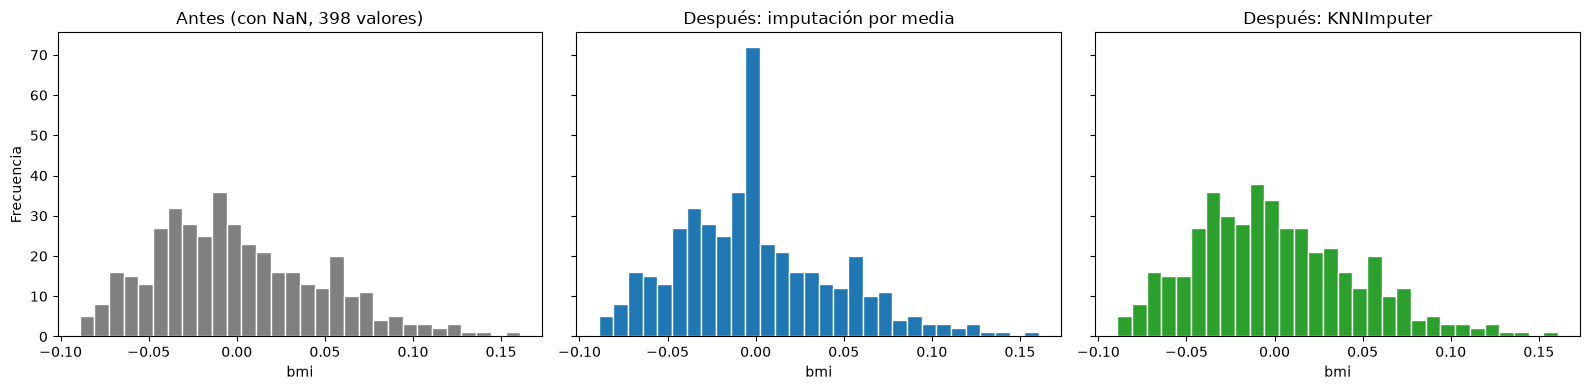

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
bins = 30

axes[0].hist(data['bmi'].dropna(), bins=bins, color='gray', edgecolor='white')
axes[0].set_title('Antes (con NaN, 398 valores)')

axes[1].hist(data_simple['bmi'], bins=bins, color='tab:blue', edgecolor='white')
axes[1].set_title('Después: imputación por media')

axes[2].hist(data_knn['bmi'], bins=bins, color='tab:green', edgecolor='white')
axes[2].set_title('Después: KNNImputer')

for ax in axes:
    ax.set_xlabel('bmi')
axes[0].set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

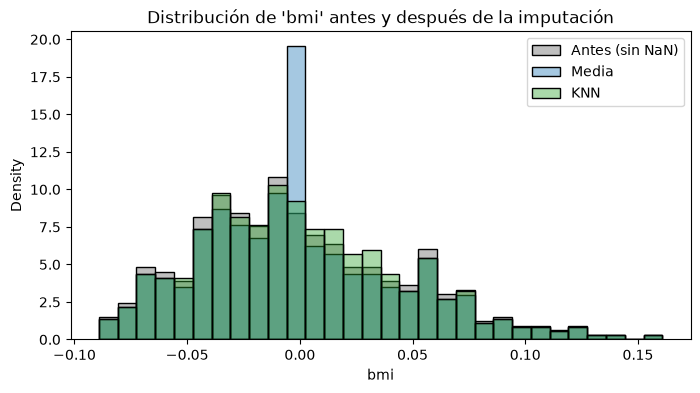

In [30]:
# Superposición para ver mejor el efecto de cada método
plt.figure(figsize=(8, 4))
sns.histplot(data['bmi'].dropna(), bins=30, color='gray', label='Antes (sin NaN)', stat='density', alpha=0.5)
sns.histplot(data_simple['bmi'], bins=30, color='tab:blue', label='Media', stat='density', alpha=0.4)
sns.histplot(data_knn['bmi'], bins=30, color='tab:green', label='KNN', stat='density', alpha=0.4)
plt.legend()
plt.title("Distribución de 'bmi' antes y después de la imputación")
plt.show()

**Observación:** con la media aparece un pico artificial en el centro de la distribución (los 44 valores imputados caen todos en la misma barra). Con KNN los valores imputados se reparten y la forma original se conserva mejor.